# Avance 2 - Paso 2: Análisis Univariado
**Proyecto:** Impacto de las Áreas Verdes en la Tasa de Hurtos (Región Metropolitana, 2023)  
**Integrantes:** Vicente Paredes, Tomás Armijo, Francisca Matamala

---

## 🎯 Objetivo
Siguiendo la **Sección 3.2** de la pauta del Avance 2, exploramos individualmente las variables más relevantes para la pregunta del proyecto, estudiando su **distribución, tendencia central, dispersión, asimetría, frecuencia de categorías y valores extremos**.

Variables analizadas (y por qué):
| Variable | Rol | Comunas con dato |
|---|---|---|
| `tasa_hurtos_100k` | $Y$: fenómeno objetivo | 52 |
| `m2_areas_verdes_per_capita` | $X$: variable explicativa principal | 44 (comunas con catastro MINVU) |
| `pct_pobreza` | Variable de contexto socioeconómico | 52 |
| Tipo de espacio (plaza / parque) | Composición de $X$ | 8.160 espacios |

Datos de entrada: `data/processed/comunas_rm_consolidado_2023.csv` (generado en el Paso 1).

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv(os.path.join('..', 'data', 'processed', 'comunas_rm_consolidado_2023.csv'))

FIG_DIR = os.path.join('..', 'figures')
os.makedirs(FIG_DIR, exist_ok=True)

# Colores fijos por variable (se mantendrán en todo el proyecto)
COLOR_Y = 'C3'        # rojo: hurtos
COLOR_X = 'C2'        # verde: áreas verdes
COLOR_CTX = 'C7'      # gris: contexto socioeconómico

print(f'Comunas cargadas: {len(df)}')

Comunas cargadas: 52


---
## 1. Variable objetivo $Y$: Tasa de hurtos por cada 100.000 habitantes
Usamos un **histograma** para ver la forma de la distribución y un **boxplot** para identificar los valores extremos.

count      52.0
mean      484.1
std       439.4
min       152.1
25%       256.2
50%       352.8
75%       524.6
max      2795.1
Name: tasa_hurtos_100k, dtype: float64

Asimetría (skew): 3.44


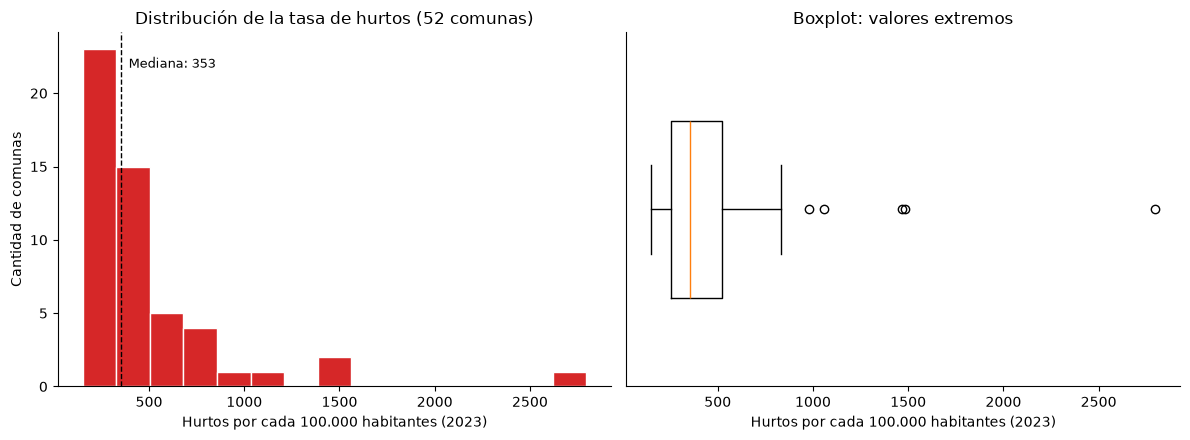

In [2]:
y = df['tasa_hurtos_100k']
print(y.describe().round(1))
print(f'\nAsimetría (skew): {y.skew():.2f}')

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))

ax1.hist(y, bins=15, color=COLOR_Y, edgecolor='white')
ax1.axvline(y.median(), color='black', linestyle='--', linewidth=1)
ax1.text(y.median() + 40, ax1.get_ylim()[1] * 0.9, f'Mediana: {y.median():.0f}', fontsize=9)
ax1.set_title('Distribución de la tasa de hurtos (52 comunas)')
ax1.set_xlabel('Hurtos por cada 100.000 habitantes (2023)')
ax1.set_ylabel('Cantidad de comunas')

ax2.boxplot(y, orientation='horizontal', widths=0.5)
ax2.set_title('Boxplot: valores extremos')
ax2.set_xlabel('Hurtos por cada 100.000 habitantes (2023)')
ax2.set_yticks([])

for ax in (ax1, ax2):
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'p2_distribucion_tasa_hurtos.png'), dpi=150, bbox_inches='tight')
plt.show()

In [3]:
# Identificación de outliers con la regla del rango intercuartílico (IQR)
q1, q3 = y.quantile([0.25, 0.75])
limite_superior = q3 + 1.5 * (q3 - q1)
print(f'Límite superior (Q3 + 1,5·IQR): {limite_superior:.1f}')

outliers_y = df[y > limite_superior][['comuna', 'tasa_hurtos_100k', 'total_hurtos_2023', 'poblacion']]
outliers_y.sort_values('tasa_hurtos_100k', ascending=False)

Límite superior (Q3 + 1,5·IQR): 927.3


,comuna,tasa_hurtos_100k,total_hurtos_2023,poblacion
22,Providencia,2795.063170,4595.0,164397.0
5,Estación Central,1481.315128,3298.0,222640.0
0,Santiago,1468.487264,8038.0,547366.0
12,La Reina,1059.585257,1049.0,99001.0
1,Cerrillos,981.185627,885.0,90197.0


In [4]:
# Concentración de los casos en números absolutos
top5 = df.nlargest(5, 'total_hurtos_2023')
porcentaje = top5['total_hurtos_2023'].sum() / df['total_hurtos_2023'].sum() * 100
print(f'Las 5 comunas con más hurtos concentran el {porcentaje:.1f}% de los casos de la RM:')
print(top5[['comuna', 'total_hurtos_2023']].to_string(index=False))

Las 5 comunas con más hurtos concentran el 45.3% de los casos de la RM:
          comuna  total_hurtos_2023
        Santiago             8038.0
     Providencia             4595.0
Estación Central             3298.0
      La Florida             3259.0
      Las Condes             2866.0


### 🔍 Interpretación de $Y$
- **Distribución muy asimétrica a la derecha** (skew = 3,44): la media (484) es bastante mayor que la mediana (353). La mayoría de las comunas tiene tasas moderadas (el 50% central está entre 256 y 525 hurtos por 100.000 hab), pero unas pocas tienen valores muy altos.
- **5 comunas atípicas:** Providencia (2.795), Estación Central (1.481), Santiago (1.468), La Reina (1.060) y Cerrillos (981). Providencia duplica a la segunda comuna.
- **Alta concentración:** las 5 comunas con más casos absolutos (Santiago, Providencia, Estación Central, La Florida y Las Condes) acumulan el **45,3%** de los hurtos de la RM.

**Limitación importante:** la tasa se calcula con la población *residente*. En comunas céntricas y comerciales (Santiago, Providencia, Estación Central) circulan diariamente muchas más personas que las que viven ahí (población flotante), por lo que la tasa tiende a **sobreestimar** el riesgo por residente en esas comunas.

**Decisión:** los outliers **no se eliminan**, porque son comunas reales y son parte del fenómeno que queremos estudiar. En el análisis de relaciones (Paso 3) se considerará su efecto (por ejemplo, revisando los resultados con y sin ellas).

---
## 2. Variable explicativa $X$: Metros cuadrados de áreas verdes por habitante
Se analizan las **44 comunas con catastro MINVU** (las 8 comunas sin catastro quedan fuera, ver Paso 1).  
En el histograma se marca como referencia el valor de **9 m²/hab**, ampliamente citado como estándar recomendado (atribuido a la OMS).

count    44.00
mean      5.10
std       4.36
min       0.18
25%       2.42
50%       3.51
75%       5.17
max      16.27
Name: m2_areas_verdes_per_capita, dtype: float64

Asimetría (skew): 1.48
Comunas con 9 m²/hab o más: 7 de 44


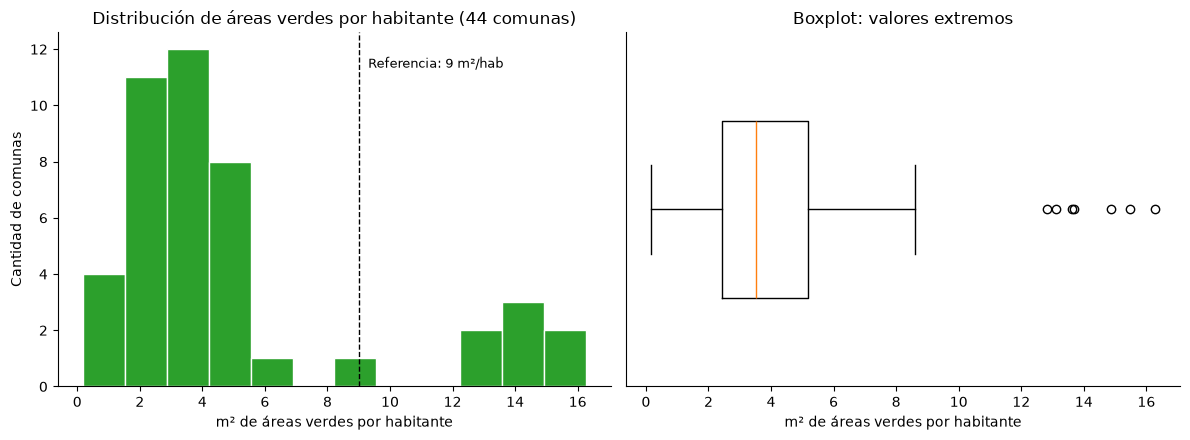

In [5]:
x = df['m2_areas_verdes_per_capita'].dropna()
print(x.describe().round(2))
print(f'\nAsimetría (skew): {x.skew():.2f}')
print(f'Comunas con 9 m²/hab o más: {(x >= 9).sum()} de {len(x)}')

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))

ax1.hist(x, bins=12, color=COLOR_X, edgecolor='white')
ax1.axvline(9, color='black', linestyle='--', linewidth=1)
ax1.text(9.3, ax1.get_ylim()[1] * 0.9, 'Referencia: 9 m²/hab', fontsize=9)
ax1.set_title('Distribución de áreas verdes por habitante (44 comunas)')
ax1.set_xlabel('m² de áreas verdes por habitante')
ax1.set_ylabel('Cantidad de comunas')

ax2.boxplot(x, orientation='horizontal', widths=0.5)
ax2.set_title('Boxplot: valores extremos')
ax2.set_xlabel('m² de áreas verdes por habitante')
ax2.set_yticks([])

for ax in (ax1, ax2):
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'p2_distribucion_m2_per_capita.png'), dpi=150, bbox_inches='tight')
plt.show()

In [6]:
q1, q3 = x.quantile([0.25, 0.75])
limite_superior = q3 + 1.5 * (q3 - q1)
print(f'Límite superior (Q3 + 1,5·IQR): {limite_superior:.2f} m²/hab\n')

print('Comunas atípicas (más áreas verdes por habitante):')
print(df[df['m2_areas_verdes_per_capita'] > limite_superior]
      .sort_values('m2_areas_verdes_per_capita', ascending=False)[['comuna', 'm2_areas_verdes_per_capita']]
      .to_string(index=False))

print('\nComunas con menos áreas verdes por habitante:')
print(df.nsmallest(5, 'm2_areas_verdes_per_capita')[['comuna', 'm2_areas_verdes_per_capita']].to_string(index=False))

Límite superior (Q3 + 1,5·IQR): 9.29 m²/hab

Comunas atípicas (más áreas verdes por habitante):
      comuna  m2_areas_verdes_per_capita
    Vitacura                   16.270196
  Huechuraba                   15.474952
    Recoleta                   14.861582
   Cerrillos                   13.692753
    La Reina                   13.629998
 Providencia                   13.104405
Lo Barnechea                   12.837707

Comunas con menos áreas verdes por habitante:
           comuna  m2_areas_verdes_per_capita
           Pirque                    0.176862
San José De Maipo                    0.190199
    Independencia                    1.017196
       San Miguel                    1.440803
      La Cisterna                    1.581885


### 🔍 Interpretación de $X$
- **Distribución asimétrica a la derecha** (skew = 1,48): la mediana es **3,5 m²/hab** y la media 5,1 m²/hab. La mitad de las comunas con catastro tiene menos de 3,5 m² por habitante.
- **Solo 7 de 44 comunas alcanzan los 9 m²/hab** de referencia: Vitacura (16,3), Huechuraba (15,5), Recoleta (14,9), Cerrillos (13,7), La Reina (13,6), Providencia (13,1) y Lo Barnechea (12,8). Son además los valores atípicos del boxplot.
- La mayoría de estas comunas son del sector oriente y de altos ingresos, pero **Recoleta y Cerrillos rompen ese patrón**. Conviene revisar qué espacios explican sus valores (por ejemplo, la presencia de grandes parques).
- En el extremo inferior hay dos casos distintos:
  - **Pirque (0,18) y San José de Maipo (0,19):** comunas semi-rurales donde el catastro urbano cubre una parte pequeña del territorio. Su valor bajo refleja la **cobertura del catastro**, no necesariamente falta de naturaleza.
  - **Independencia (1,0), San Miguel (1,4) y La Cisterna (1,6):** comunas urbanas densas con un **déficit real** de áreas verdes.

---
## 3. Variable de contexto: Porcentaje de pobreza por ingresos
Esta variable no es parte directa de la pregunta, pero la incorporamos porque puede influir tanto en las áreas verdes como en los hurtos (variable de contexto).

count    52.0
mean     14.5
std       5.4
min       0.8
25%      12.0
50%      15.2
75%      18.4
max      23.3
Name: pct_pobreza, dtype: float64

Asimetría (skew): -0.80
Comunas con mayor pobreza:
    comuna  pct_pobreza
La Pintana     0.233008
     Alhué     0.232055
 San Pedro     0.222198

Comunas con menor pobreza:
      comuna  pct_pobreza
    Vitacura     0.008107
 Providencia     0.011865
Lo Barnechea     0.027503


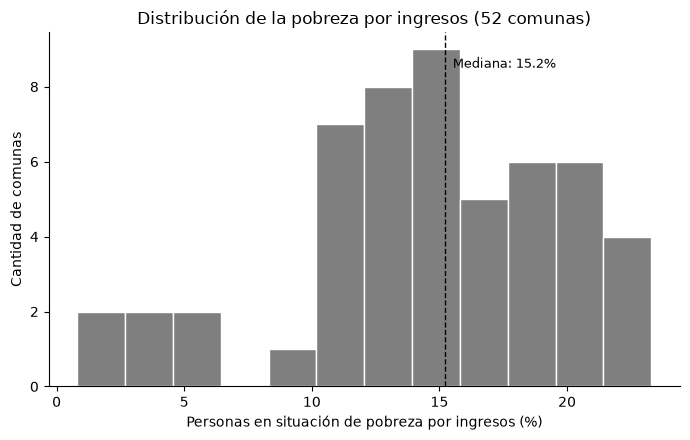

In [7]:
p = df['pct_pobreza'] * 100   # en porcentaje
print(p.describe().round(1))
print(f'\nAsimetría (skew): {p.skew():.2f}')

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.hist(p, bins=12, color=COLOR_CTX, edgecolor='white')
ax.axvline(p.median(), color='black', linestyle='--', linewidth=1)
ax.text(p.median() + 0.3, ax.get_ylim()[1] * 0.9, f'Mediana: {p.median():.1f}%', fontsize=9)
ax.set_title('Distribución de la pobreza por ingresos (52 comunas)')
ax.set_xlabel('Personas en situación de pobreza por ingresos (%)')
ax.set_ylabel('Cantidad de comunas')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'p2_distribucion_pobreza.png'), dpi=150, bbox_inches='tight')
plt.show()

print('Comunas con mayor pobreza:')
print(df.nlargest(3, 'pct_pobreza')[['comuna', 'pct_pobreza']].to_string(index=False))
print('\nComunas con menor pobreza:')
print(df.nsmallest(3, 'pct_pobreza')[['comuna', 'pct_pobreza']].to_string(index=False))

### 🔍 Interpretación de la pobreza
- **Asimetría hacia la izquierda** (skew = -0,80): la mayoría de las comunas está entre 12% y 18% de pobreza (mediana 15,2%), y existe un **pequeño grupo con pobreza muy baja**: Vitacura (0,8%), Providencia (1,2%) y Lo Barnechea (2,8%).
- Las comunas con mayor pobreza son La Pintana (23,3%), Alhué (23,2%) y San Pedro (22,2%).
- **Observación clave para el Paso 3:** las comunas con menos pobreza (Vitacura, Providencia, Lo Barnechea) son **las mismas** que aparecen con más áreas verdes por habitante. Es decir, la pobreza podría estar relacionada con $X$, y por lo tanto debe considerarse al analizar la relación entre áreas verdes y hurtos.

---
## 4. Composición de las áreas verdes: plazas vs. parques
Variable categórica: frecuencia de cada tipo de espacio público en la RM. Usamos un **gráfico de barras**, adecuado para comparar categorías.

         cantidad  porcentaje
Plazas       7550        92.5
Parques       610         7.5


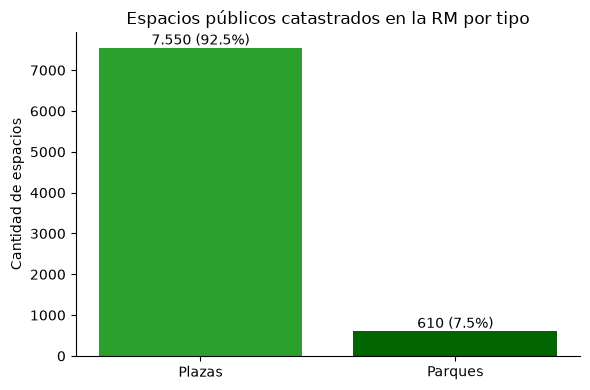

In [8]:
conteo = pd.Series({
    'Plazas': int(df['cantidad_plazas'].sum()),
    'Parques': int(df['cantidad_parques'].sum()),
})
porcentaje = conteo / conteo.sum() * 100
print(pd.DataFrame({'cantidad': conteo, 'porcentaje': porcentaje.round(1)}))

fig, ax = plt.subplots(figsize=(6, 4))
barras = ax.bar(conteo.index, conteo.values, color=[COLOR_X, 'darkgreen'])
for barra, pct in zip(barras, porcentaje):
    ax.text(barra.get_x() + barra.get_width() / 2, barra.get_height() + 80,
            f'{int(barra.get_height()):,} ({pct:.1f}%)'.replace(',', '.'), ha='center', fontsize=10)
ax.set_title('Espacios públicos catastrados en la RM por tipo')
ax.set_ylabel('Cantidad de espacios')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'p2_plazas_vs_parques.png'), dpi=150, bbox_inches='tight')
plt.show()

### 🔍 Interpretación
- El **92,5%** de los 8.160 espacios catastrados son **plazas** y solo el **7,5%** son parques.
- Por esto, contar "cantidad de espacios" mide principalmente plazas pequeñas. Para representar la disponibilidad de áreas verdes es más adecuado usar la **superficie (m² por habitante)**, que es la variable $X$ elegida.

---
## 5. Resumen de hallazgos del análisis univariado
1. **$Y$ (tasa de hurtos)** está muy concentrada: la mayoría de las comunas tiene tasas moderadas, pero unas pocas comunas céntricas/comerciales (Providencia, Estación Central, Santiago) presentan valores extremos, probablemente influidos por la población flotante.
2. **$X$ (m² por habitante)** también es asimétrica: la mitad de las comunas tiene menos de 3,5 m²/hab y solo 7 de 44 superan los 9 m²/hab.
3. **La pobreza** muestra un grupo pequeño de comunas con pobreza muy baja, que coincide con las comunas con más áreas verdes.
4. **Las plazas dominan** el catastro, por lo que la superficie es mejor medida de $X$ que el conteo de espacios.

### Decisiones para el Paso 3 (relaciones entre variables)
- Mantener los outliers, pero revisar si los resultados cambian al excluirlos.
- Como ambas variables son asimétricas, observar la relación con cuidado (por ejemplo, usar la mediana en las comparaciones).
- Incorporar la pobreza al analizar la relación $X$ vs $Y$, ya que parece estar relacionada con ambas.